# Healthcare Appointment Data Analysis

## Project Overview

This project analyzes healthcare appointment data to identify patterns in
appointment scheduling, patient attendance, cancellations, and no-shows.

The analysis focuses on appointment trends across time, visit reasons,
doctors, appointment status, and appointment hours.

## 1. Import Libraries

We import the Python libraries required for data manipulation,
numerical analysis, and data visualization.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Dataset

The healthcare appointment dataset is loaded into a Pandas DataFrame
for further analysis.

In [55]:
health=pd.read_csv("C:\\Users\\saiad\\OneDrive\\Documents\\Medical_EDA\\data\\appointments.csv")

## 3. Initial Data Inspection

We inspect the first and last few records and examine the structure,
data types, and number of non-null values in the dataset.

In [57]:
health.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   appointment_id    200 non-null    object
 1   patient_id        200 non-null    object
 2   doctor_id         200 non-null    object
 3   appointment_date  200 non-null    object
 4   appointment_time  200 non-null    object
 5   reason_for_visit  200 non-null    object
 6   status            200 non-null    object
dtypes: object(7)
memory usage: 11.1+ KB


In [58]:
health.head()

,appointment_id,patient_id,doctor_id,appointment_date,appointment_time,reason_for_visit,status
0,A001,P034,D009,2023-08-09,15:15:00,Therapy,Scheduled
1,A002,P032,D004,2023-06-09,14:30:00,Therapy,No-show
2,A003,P048,D004,2023-06-28,8:00:00,Consultation,Cancelled
3,A004,P025,D006,2023-09-01,9:15:00,Consultation,Cancelled
4,A005,P040,D003,2023-07-06,12:45:00,Emergency,No-show


In [59]:
health.tail()

,appointment_id,patient_id,doctor_id,appointment_date,appointment_time,reason_for_visit,status
195,A196,P045,D006,2023-10-26,9:45:00,Checkup,Cancelled
196,A197,P001,D005,2023-04-01,13:30:00,Emergency,No-show
197,A198,P022,D006,2023-05-15,8:30:00,Therapy,No-show
198,A199,P017,D001,2023-05-01,12:45:00,Follow-up,Completed
199,A200,P007,D005,2023-12-30,10:15:00,Consultation,Cancelled


## 4. Data Quality Check

We check for missing values, duplicate records, unique values, and
basic statistical information to understand the quality of the dataset.

In [60]:
health.describe(include='all')

,appointment_id,patient_id,doctor_id,appointment_date,appointment_time,reason_for_visit,status
count,200,200,200,200,200,200,200
unique,200,48,10,158,40,5,4
top,A001,P012,D005,2023-08-16,15:00:00,Checkup,No-show
freq,1,10,29,5,9,45,52


In [61]:
health.nunique()

appointment_id      200
patient_id           48
doctor_id            10
appointment_date    158
appointment_time     40
reason_for_visit      5
status                4
dtype: int64

In [62]:
health.isnull().sum()

appointment_id      0
patient_id          0
doctor_id           0
appointment_date    0
appointment_time    0
reason_for_visit    0
status              0
dtype: int64

In [63]:
health.duplicated().sum()

np.int64(0)

In [64]:
health['status'].value_counts()

status
No-show      52
Scheduled    51
Cancelled    51
Completed    46
Name: count, dtype: int64

In [65]:
health['reason_for_visit'].value_counts()

reason_for_visit
Checkup         45
Consultation    43
Therapy         42
Follow-up       41
Emergency       29
Name: count, dtype: int64

In [66]:
health['doctor_id'].value_counts()

doctor_id
D005    29
D001    25
D006    24
D003    22
D002    21
D010    19
D009    17
D008    16
D004    14
D007    13
Name: count, dtype: int64

In [67]:
health['patient_id'].value_counts().head(10)

patient_id
P012    10
P005     8
P016     7
P036     7
P029     7
P049     7
P035     7
P010     6
P023     6
P026     6
Name: count, dtype: int64

In [68]:
health['appointment_date'].head(10)

0    2023-08-09
1    2023-06-09
2    2023-06-28
3    2023-09-01
4    2023-07-06
5    2023-06-19
6    2023-04-09
7    2023-05-24
8    2023-03-05
9    2023-01-13
Name: appointment_date, dtype: object

In [69]:
health['appointment_date'].tail(10)

190    2023-04-12
191    2023-08-31
192    2023-09-15
193    2023-04-06
194    2023-08-19
195    2023-10-26
196    2023-04-01
197    2023-05-15
198    2023-05-01
199    2023-12-30
Name: appointment_date, dtype: object

## 5. Data Cleaning and Feature Engineering

The appointment date is converted to datetime format. Additional
time-based features such as appointment hour, year, month, month name,
and day of the week are created for analysis.

In [70]:
health['appointment_date']=pd.to_datetime(
    health['appointment_date']
)

In [71]:
health['appointment_date'].dtype

dtype('<M8[ns]')

In [72]:
health.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   appointment_id    200 non-null    object        
 1   patient_id        200 non-null    object        
 2   doctor_id         200 non-null    object        
 3   appointment_date  200 non-null    datetime64[ns]
 4   appointment_time  200 non-null    object        
 5   reason_for_visit  200 non-null    object        
 6   status            200 non-null    object        
dtypes: datetime64[ns](1), object(6)
memory usage: 11.1+ KB


In [73]:
health['appointment_time'].head(10)

0    15:15:00
1    14:30:00
2     8:00:00
3     9:15:00
4    12:45:00
5    16:15:00
6    10:30:00
7     8:45:00
8    13:45:00
9    15:30:00
Name: appointment_time, dtype: object

In [74]:
health['appointment_time'] = pd.to_datetime(
    health['appointment_time'],
    format='%H:%M:%S'
).dt.time

In [75]:
health.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   appointment_id    200 non-null    object        
 1   patient_id        200 non-null    object        
 2   doctor_id         200 non-null    object        
 3   appointment_date  200 non-null    datetime64[ns]
 4   appointment_time  200 non-null    object        
 5   reason_for_visit  200 non-null    object        
 6   status            200 non-null    object        
dtypes: datetime64[ns](1), object(6)
memory usage: 11.1+ KB


In [76]:
health['appointment_time'].head()

0    15:15:00
1    14:30:00
2    08:00:00
3    09:15:00
4    12:45:00
Name: appointment_time, dtype: object

In [80]:
health['appointment_hour']=health['appointment_time'].apply(
    lambda x :x.hour
)

In [82]:
health[['appointment_time', 'appointment_hour']].head(10)

,appointment_time,appointment_hour
0,15:15:00,15
1,14:30:00,14
2,08:00:00,8
3,09:15:00,9
4,12:45:00,12
5,16:15:00,16
6,10:30:00,10
7,08:45:00,8
8,13:45:00,13
9,15:30:00,15


In [83]:
health.head()

,appointment_id,patient_id,doctor_id,appointment_date,appointment_time,reason_for_visit,status,appointment_hour
0,A001,P034,D009,2023-08-09,15:15:00,Therapy,Scheduled,15
1,A002,P032,D004,2023-06-09,14:30:00,Therapy,No-show,14
2,A003,P048,D004,2023-06-28,08:00:00,Consultation,Cancelled,8
3,A004,P025,D006,2023-09-01,09:15:00,Consultation,Cancelled,9
4,A005,P040,D003,2023-07-06,12:45:00,Emergency,No-show,12


In [84]:
health['appointment_year'] = health['appointment_date'].dt.year
health['appointment_month'] = health['appointment_date'].dt.month
health['appointment_month_name'] = health['appointment_date'].dt.month_name()
health['appointment_day'] = health['appointment_date'].dt.day_name()

In [85]:
health[['appointment_date',
        'appointment_year',
        'appointment_month',
        'appointment_month_name',
        'appointment_day']].head(10)

,appointment_date,appointment_year,appointment_month,appointment_month_name,appointment_day
0,2023-08-09,2023,8,August,Wednesday
1,2023-06-09,2023,6,June,Friday
2,2023-06-28,2023,6,June,Wednesday
3,2023-09-01,2023,9,September,Friday
4,2023-07-06,2023,7,July,Thursday
5,2023-06-19,2023,6,June,Monday
6,2023-04-09,2023,4,April,Sunday
7,2023-05-24,2023,5,May,Wednesday
8,2023-03-05,2023,3,March,Sunday
9,2023-01-13,2023,1,January,Friday


In [86]:
health['appointment_month_name'].value_counts()

appointment_month_name
April        25
January      20
May          19
March        19
June         18
November     17
July         16
August       15
February     14
October      14
December     12
September    11
Name: count, dtype: int64

## 6. Exploratory Data Analysis

### 6.1 Monthly Appointment Analysis

We analyze appointment volume across months to identify seasonal
patterns and periods with higher or lower appointment activity.

In [88]:
monthly_counts = health['appointment_month'].value_counts().sort_index()

In [89]:
health.head()

,appointment_id,patient_id,doctor_id,appointment_date,appointment_time,reason_for_visit,status,appointment_hour,appointment_year,appointment_month,appointment_month_name,appointment_day
0,A001,P034,D009,2023-08-09,15:15:00,Therapy,Scheduled,15,2023,8,August,Wednesday
1,A002,P032,D004,2023-06-09,14:30:00,Therapy,No-show,14,2023,6,June,Friday
2,A003,P048,D004,2023-06-28,08:00:00,Consultation,Cancelled,8,2023,6,June,Wednesday
3,A004,P025,D006,2023-09-01,09:15:00,Consultation,Cancelled,9,2023,9,September,Friday
4,A005,P040,D003,2023-07-06,12:45:00,Emergency,No-show,12,2023,7,July,Thursday


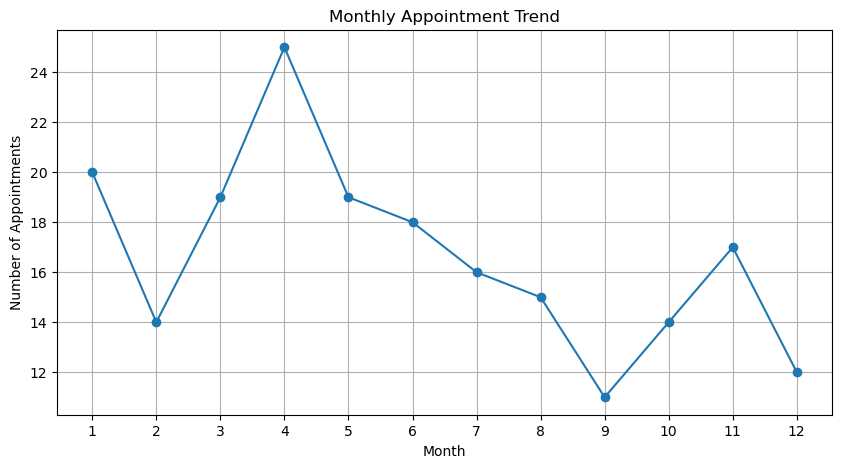

In [90]:
monthly_counts.plot(kind='line', marker='o', figsize=(10,5))

plt.title('Monthly Appointment Trend')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(range(1, 13))
plt.grid()
plt.show()

### 6.2 Appointment Analysis by Day of Week

We analyze appointment distribution across days of the week to identify
which days experience higher or lower appointment activity.

In [91]:
day_counts = health['appointment_day'].value_counts()
day_counts

appointment_day
Wednesday    37
Tuesday      37
Thursday     28
Monday       26
Sunday       26
Friday       23
Saturday     23
Name: count, dtype: int64

In [92]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_counts = health['appointment_day'].value_counts().reindex(day_order)

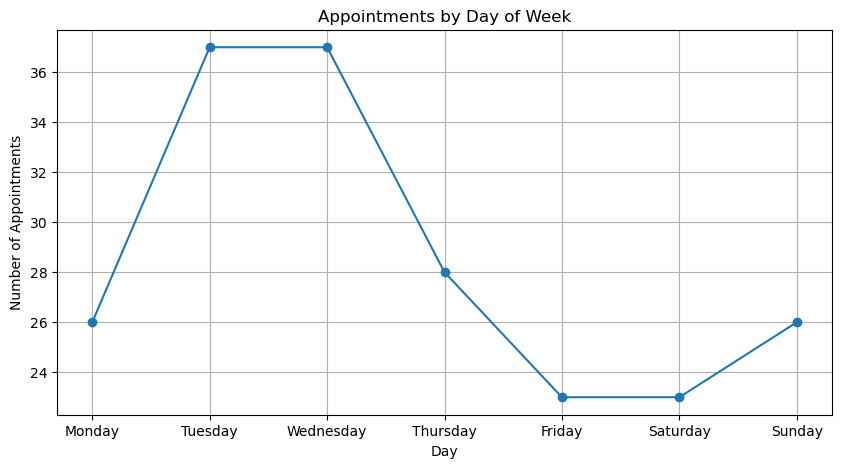

In [102]:
day_counts.plot(kind='line',marker='o', figsize=(10,5))

plt.title('Appointments by Day of Week')
plt.xlabel('Day')
plt.ylabel('Number of Appointments')
plt.grid()
plt.show()

### 6.3 Appointment Status Analysis

We examine the distribution of appointment outcomes, including
completed, scheduled, cancelled, and no-show appointments.

In [103]:
status_counts = health['status'].value_counts()
status_counts

status
No-show      52
Scheduled    51
Cancelled    51
Completed    46
Name: count, dtype: int64

In [104]:
status_percentage = health['status'].value_counts(normalize=True) * 100
status_percentage.round(2)

status
No-show      26.0
Scheduled    25.5
Cancelled    25.5
Completed    23.0
Name: proportion, dtype: float64

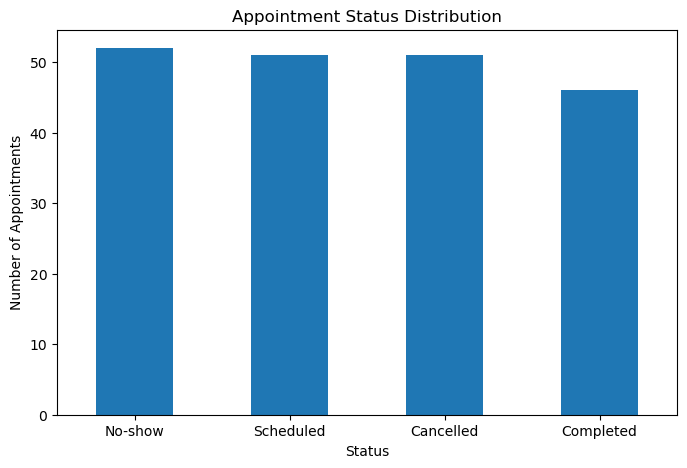

In [110]:
status_counts.plot(kind='bar', figsize=(8,5))

plt.title('Appointment Status Distribution')
plt.xlabel('Status')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=0)

plt.show()

### 6.4 Analysis by Reason for Visit

We analyze the most common reasons for appointments and compare the
frequency of different visit types.

In [106]:
reason_counts = health['reason_for_visit'].value_counts()
reason_counts

reason_for_visit
Checkup         45
Consultation    43
Therapy         42
Follow-up       41
Emergency       29
Name: count, dtype: int64

### 6.5 Visit Reason vs Appointment Status

A crosstab is used to compare visit reasons with appointment outcomes.
Row-wise percentages are calculated to make comparisons between visit
types easier.

In [107]:
reason_status = pd.crosstab(
    health['reason_for_visit'],
    health['status']
)

reason_status

status,Cancelled,Completed,No-show,Scheduled
reason_for_visit,,,,
Checkup,8,16,10,11
Consultation,15,4,11,13
Emergency,8,5,10,6
Follow-up,10,12,6,13
Therapy,10,9,15,8


In [108]:
reason_status_percentage = pd.crosstab(
    health['reason_for_visit'],
    health['status'],
    normalize='index'
) * 100

reason_status_percentage.round(2)

status,Cancelled,Completed,No-show,Scheduled
reason_for_visit,,,,
Checkup,17.78,35.56,22.22,24.44
Consultation,34.88,9.30,25.58,30.23
Emergency,27.59,17.24,34.48,20.69
Follow-up,24.39,29.27,14.63,31.71
Therapy,23.81,21.43,35.71,19.05


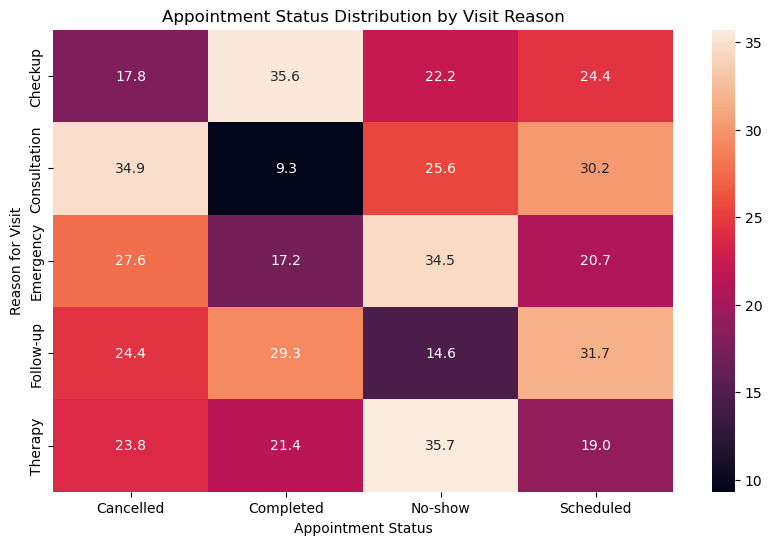

In [120]:
reason_status_percentage = pd.crosstab(
    health['reason_for_visit'],
    health['status'],
    normalize='index'
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    reason_status_percentage,
    annot=True,
    fmt='.1f'
)

plt.title('Appointment Status Distribution by Visit Reason')
plt.xlabel('Appointment Status')
plt.ylabel('Reason for Visit')
plt.show()

Key Observation:

Therapy had the highest no-show proportion (35.71%), followed by Emergency visits (34.48%). Consultation had the highest cancellation proportion (34.88%) and the lowest completion proportion (9.30%). Checkup appointments had the highest completion proportion (35.56%).

### 6.6 Doctor-wise Appointment Analysis

We analyze appointment volume across doctors and compare appointment
outcomes for each doctor.

In [109]:
doctor_counts = health['doctor_id'].value_counts()
doctor_counts

doctor_id
D005    29
D001    25
D006    24
D003    22
D002    21
D010    19
D009    17
D008    16
D004    14
D007    13
Name: count, dtype: int64

In [111]:
doctor_counts = health['doctor_id'].value_counts()
doctor_counts

doctor_id
D005    29
D001    25
D006    24
D003    22
D002    21
D010    19
D009    17
D008    16
D004    14
D007    13
Name: count, dtype: int64

In [112]:
doctor_status = pd.crosstab(
    health['doctor_id'],
    health['status']
)

doctor_status

status,Cancelled,Completed,No-show,Scheduled
doctor_id,,,,
D001,7,6,7,5
D002,8,5,1,7
D003,4,6,7,5
D004,3,3,5,3
D005,6,4,9,10
D006,6,5,6,7
D007,5,5,2,1
D008,5,4,4,3
D009,4,3,6,4


In [113]:
doctor_status_percentage = pd.crosstab(
    health['doctor_id'],
    health['status'],
    normalize='index'
) * 100

doctor_status_percentage.round(2)

status,Cancelled,Completed,No-show,Scheduled
doctor_id,,,,
D001,28.00,24.00,28.00,20.00
D002,38.10,23.81,4.76,33.33
D003,18.18,27.27,31.82,22.73
D004,21.43,21.43,35.71,21.43
D005,20.69,13.79,31.03,34.48
D006,25.00,20.83,25.00,29.17
D007,38.46,38.46,15.38,7.69
D008,31.25,25.00,25.00,18.75
D009,23.53,17.65,35.29,23.53


### 6.7 Appointment Hour Analysis

We analyze appointment volume across different hours of the day and
examine how appointment outcomes vary by appointment time.

In [114]:
hour_counts = health['appointment_hour'].value_counts().sort_index()
hour_counts

appointment_hour
8     21
9     17
10    19
11    18
12    21
13    20
14    20
15    28
16    15
17    21
Name: count, dtype: int64

In [115]:
doctor_status_percentage = pd.crosstab(
    health['appointment_hour'],
    health['status'],
    normalize='index'
) * 100

doctor_status_percentage.round(2)

status,Cancelled,Completed,No-show,Scheduled
appointment_hour,,,,
8,28.57,19.05,19.05,33.33
9,29.41,11.76,35.29,23.53
10,26.32,26.32,26.32,21.05
11,16.67,22.22,27.78,33.33
12,23.81,42.86,9.52,23.81
13,25.00,25.00,25.00,25.00
14,30.00,20.00,25.00,25.00
15,28.57,25.00,28.57,17.86
16,33.33,13.33,26.67,26.67


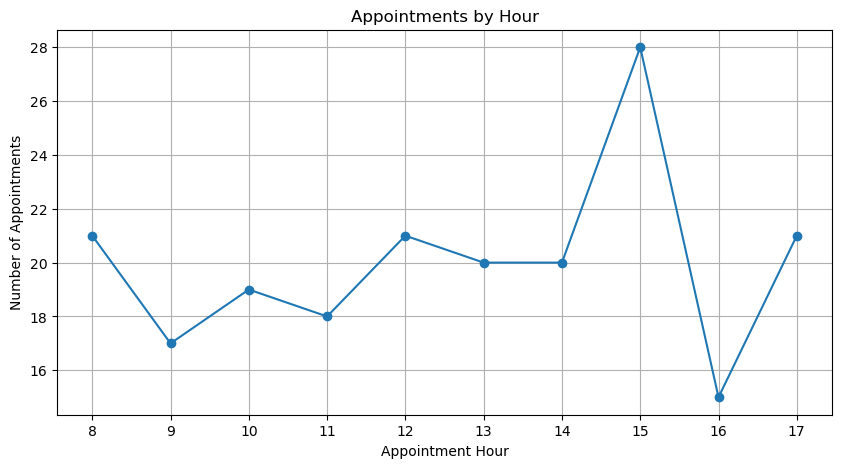

In [116]:
hour_counts.plot(kind='line', marker='o', figsize=(10,5))

plt.title('Appointments by Hour')
plt.xlabel('Appointment Hour')
plt.ylabel('Number of Appointments')
plt.xticks(range(8, 18))
plt.grid()
plt.show()

### 6.8 Doctor vs Reason for Visit

We compare doctors with different visit reasons to understand how
appointment types are distributed across doctors.

In [117]:
doctor_reason = pd.crosstab(
    health['doctor_id'],
    health['reason_for_visit']
)

doctor_reason

reason_for_visit,Checkup,Consultation,Emergency,Follow-up,Therapy
doctor_id,,,,,
D001,3,4,6,8,4
D002,5,3,2,7,4
D003,3,8,2,5,4
D004,2,5,3,1,3
D005,9,6,3,1,10
D006,10,3,6,4,1
D007,5,2,0,3,3
D008,1,5,1,4,5
D009,1,4,3,4,5


## 7. Key Insights

- April recorded the highest number of appointments, while September
  recorded the lowest.

- Tuesday and Wednesday had the highest appointment volume among the
  days of the week.

- Cancelled and no-show appointments together represented 51.5% of
  all recorded appointments.

- Only 23% of all appointments were completed.

- Therapy had the highest no-show proportion at 35.71%.

- Emergency appointments had a 34.48% no-show proportion.

- Consultation had the highest cancellation proportion at 34.88%
  and the lowest completion proportion at 9.30%.

- 3 PM was the busiest appointment hour with 28 appointments, while
  4 PM had the lowest volume with 15 appointments.

- D004 had the highest observed doctor-level no-show proportion at
  35.71%, while D007 had the highest completion proportion at 38.46%.

## 8. Conclusion

The analysis of the healthcare appointment dataset revealed meaningful
patterns in appointment scheduling and outcomes.

Appointment volume varied across months, days, and hours, with 3 PM
being the busiest appointment hour. Appointment outcomes also varied
considerably across visit reasons and doctors.

A notable finding was that cancelled and no-show appointments together
accounted for 51.5% of all records, while completed appointments
represented 23%. Therapy and Emergency appointments showed relatively
high no-show proportions, while Consultation appointments showed a
high cancellation proportion and low completion proportion.

These findings can help identify appointment patterns that may require
further investigation and can potentially support better scheduling,
attendance monitoring, and appointment management.